Marcas a clasificar (18 categorías):
marca_modelo
Vita              1806
Amann Girrbach     307
Creation           243
Aidite             194
Anax Dent          121
Huge                88
Jensen              50
Scheftner           28
Otras_Marcas        27
Phrozen             23
Asiga               13
Hass                11
Medit                9
Roko                 8
Dekema               6
Renfert              6
Dess                 5
Exocad               5
Name: count, dtype: int64


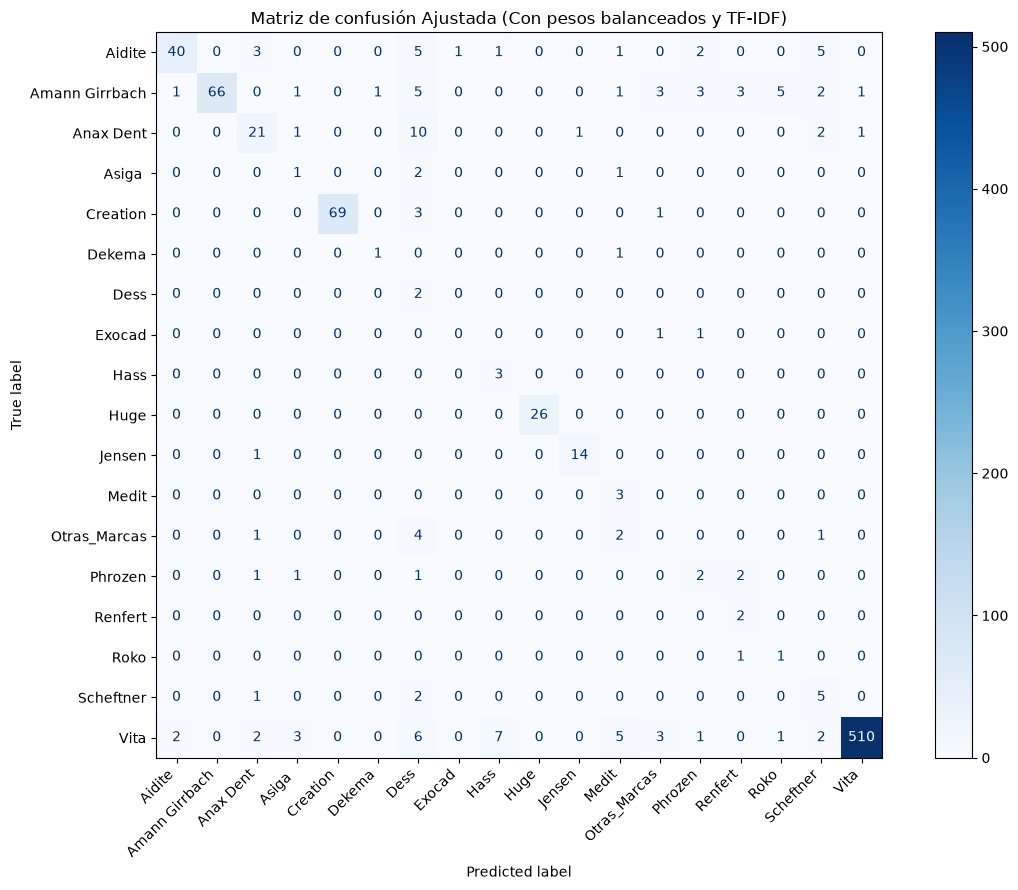


Exactitud del modelo: 0.8655

Reporte de Clasificación Detallado:
                precision    recall  f1-score   support

        Aidite       0.93      0.69      0.79        58
Amann Girrbach       1.00      0.72      0.84        92
     Anax Dent       0.70      0.58      0.64        36
        Asiga        0.14      0.25      0.18         4
      Creation       1.00      0.95      0.97        73
        Dekema       0.50      0.50      0.50         2
          Dess       0.05      1.00      0.10         2
        Exocad       0.00      0.00      0.00         2
          Hass       0.27      1.00      0.43         3
          Huge       1.00      1.00      1.00        26
        Jensen       0.93      0.93      0.93        15
         Medit       0.21      1.00      0.35         3
  Otras_Marcas       0.00      0.00      0.00         8
       Phrozen       0.22      0.29      0.25         7
       Renfert       0.25      1.00      0.40         2
          Roko       0.14      0.50 

In [1]:
# ==========================================
# 1. Cargamos librerías
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report
)
from scipy.sparse import hstack

# ==========================================
# 2. Carga y preparación inicial del Excel
# ==========================================
df = pd.read_excel("Datos_CLV_2026_Tec_v2.xlsx", sheet_name="Existencias_04_09_2026")
df.columns = df.columns.astype(str).str.strip()

# Identificación precisa de columnas
col_existencia = [c for c in df.columns if 'existenc' in c.lower()][0]
col_valor = [c for c in df.columns if 'valor' in c.lower()][0]
col_marca = [c for c in df.columns if 'marca' in c.lower()][0]

# Priorizamos 'nombre_articulo' para evitar tomar el código entero de la columna A
cols_nombre = [c for c in df.columns if 'nombre_articulo' in c.lower()]
col_articulo = cols_nombre[0] if cols_nombre else [c for c in df.columns if 'articulo' in c.lower()][0]

# Eliminamos registros sin marca
df = df.dropna(subset=[col_marca]).copy()

# ==========================================
# 3. Agrupación de marcas poco frecuentes
# ==========================================
UMBRAL_REGISTROS = 5
conteo_marcas = df[col_marca].value_counts()
marcas_principales = conteo_marcas[conteo_marcas >= UMBRAL_REGISTROS].index

df['marca_modelo'] = df[col_marca].apply(
    lambda x: x if x in marcas_principales else 'Otras_Marcas'
)

print(f"Marcas a clasificar ({len(df['marca_modelo'].unique())} categorías):")
print(df['marca_modelo'].value_counts())

# ==========================================
# 4. Limpieza de nulos y Conversión a String
# ==========================================
df[col_existencia] = df[col_existencia].fillna(0)
df[col_valor] = df[col_valor].fillna(0)

# CONVERSIÓN CRÍTICA A CADENA DE TEXTO (evita AttributeError)
df[col_articulo] = df[col_articulo].fillna('').astype(str)

# Variable de Precio Unitario (evitando división por 0)
df['precio_unitario'] = np.where(
    df[col_existencia] > 0, 
    df[col_valor] / df[col_existencia], 
    0
)

# ==========================================
# 5. Construcción de características (X)
# ==========================================
# A) Numéricas escaladas
num_features = df[[col_existencia, col_valor, 'precio_unitario']]
escalar = StandardScaler()
X_num_scaled = escalar.fit_transform(num_features)

# B) Texto con TF-IDF
tfidf = TfidfVectorizer(max_features=100)
X_text_tfidf = tfidf.fit_transform(df[col_articulo])

# C) Matriz combinada
X_combined = hstack([X_num_scaled, X_text_tfidf])
y = df['marca_modelo']

# ==========================================
# 6. División en Entrenamiento y Prueba
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.3, random_state=42, stratify=y
)

# ==========================================
# 7. Regresión Logística Multinomial
# ==========================================
algoritmo = LogisticRegression(
    solver='lbfgs',
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)
algoritmo.fit(X_train, y_train)

# ==========================================
# 8. Evaluación y Gráficos
# ==========================================
y_pred = algoritmo.predict(X_test)

matriz = confusion_matrix(y_test, y_pred, labels=algoritmo.classes_)

fig, ax = plt.subplots(figsize=(12, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=algoritmo.classes_)
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Matriz de confusión Ajustada (Con pesos balanceados y TF-IDF)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nExactitud del modelo:", round(accuracy_score(y_test, y_pred), 4))
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred, zero_division=0))

Implementación del modelo: Se desarrolló un algoritmo de Regresión Logística Multinomial para clasificar automáticamente la variable dependiente marca.

Variables predictoras y su tratamiento:

Variables cuantitativas: Se utilizaron existencia y valor_total_inventario, ambas estandarizadas mediante StandardScaler. Además, se incorporó la variable derivada precio_unitario (valor_total_inventario / existencia) para diferenciar segmentos de costo entre productos.

Variable cualitativa (texto): La variable nombre_articulo fue procesada mediante TF-IDF para extraer términos y patrones distintivos que facilitan la identificación de las diferentes marcas.

Ajuste de datos: Para garantizar una partición estratificada adecuada, las marcas con menos de cinco registros fueron agrupadas en la categoría Otras_Marcas.

Control de sesgo: Se utilizó el parámetro class_weight='balanced' para compensar el desbalance de clases, penalizando los errores en las categorías minoritarias y evitando que el modelo favoreciera excesivamente a la marca predominante (Vita).

Resultados: El modelo produjo una matriz de confusión equilibrada y mostró un alto nivel de precisión en marcas relevantes como Aidite (40 aciertos), Amann Girrbach (66), Creation (69), Huge (26) y Vita (510).

Evaluación: Los valores bajos observados (por ejemplo, "1" o "2") corresponden a aciertos puntuales en el conjunto de prueba, que representó el 30 % de los datos, para marcas con una presencia reducida en el inventario.

Conclusión e impacto: La integración de variables cuantitativas, técnicas de procesamiento de texto y estrategias de balanceo de clases permitió construir una herramienta eficaz para automatizar la clasificación de marcas en el inventario. Esto contribuye a reducir errores de registro, mejorar la calidad de los datos y optimizar los procesos de gestión comercial.